In [1]:
import os
import sys
import platform
import subprocess
import psutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)

os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["OMP_DYNAMIC"] = "FALSE"
os.environ["OMP_PROC_BIND"] = "true"

exe_name = "src/matmul_a3.exe" if platform.system() == "Windows" else "src/matmul_a3"
compile_cmd = ["gcc", "-O2", "-fopenmp", "src/matmul_a3.c", "-o", exe_name]
if platform.system() == "Windows":
    compile_cmd.append("-lpsapi")
else:
    compile_cmd.append("-lm")

subprocess.run(compile_cmd, check=True)
gcc_ver = subprocess.check_output(["gcc", "--version"]).decode().splitlines()[0]

env_info = {
    "OS": f"{platform.system()} {platform.release()}",
    "Processor": platform.processor(),
    "Physical_Cores": psutil.cpu_count(logical=False),
    "Logical_Processors": psutil.cpu_count(logical=True),
    "RAM_GB": round(psutil.virtual_memory().total / (1024**3), 2),
    "C_Compiler": gcc_ver,
    "Compiler_Flags": "-O2 -fopenmp",
    "OMP_Proc_Bind": os.environ["OMP_PROC_BIND"],
    "Python_Version": platform.python_version(),
    "NumPy_Version": np.__version__
}
pd.DataFrame([env_info])

,OS,Processor,Physical_Cores,Logical_Processors,RAM_GB,C_Compiler,Compiler_Flags,OMP_Proc_Bind,Python_Version,NumPy_Version
0,Windows 11,"Intel64 Family 6 Model 170 Stepping 4, Genuine...",16,22,15.37,"gcc (MinGW-W64 x86_64-ucrt-posix-seh, built by...",-O2 -fopenmp,true,3.14.6,2.4.6


In [2]:
def generate_ref_matrix(n, seed):
    mat = np.zeros((n, n), dtype=np.float64)
    state = seed & 0xFFFFFFFFFFFFFFFF
    for i in range(n):
        for j in range(n):
            state = (state * 6364136223846793005 + 1442695040888963407) & 0xFFFFFFFFFFFFFFFF
            mat[i, j] = (state >> 11) * (1.0 / 9007199254740992.0)
    return mat

n_val = 32
seed_val = 42
rtol = 1e-12
atol = 1e-12

A_ref = generate_ref_matrix(n_val, seed_val)
B_ref = generate_ref_matrix(n_val, seed_val + 1)
C_ref = np.matmul(A_ref, B_ref)

configs_to_validate = [("seq", 1)] + [("omp", p) for p in [1, 2, 4, 8, 16, 22, 32]]
val_rows = []

for method, p in configs_to_validate:
    id_out = subprocess.check_output([exe_name, "identity", method, str(n_val), str(p), "0", "1", str(seed_val)]).decode().strip().split(",")
    z_out = subprocess.check_output([exe_name, "zero", method, str(n_val), str(p), "0", "1", str(seed_val)]).decode().strip().split(",")
    dump_out = subprocess.check_output([exe_name, "dump", method, str(n_val), str(p), "0", "1", str(seed_val)]).decode().strip().split(",")
    C_out = np.array([float(x) for x in dump_out], dtype=np.float64).reshape((n_val, n_val))
    max_err = float(np.max(np.abs(C_out - C_ref)))
    passed = bool(np.allclose(C_out, C_ref, rtol=rtol, atol=atol))
    val_rows.append({
        "Method": "Sequential_Baseline" if method == "seq" else "OpenMP_Parallel",
        "Threads_p": p,
        "N": n_val,
        "Identity_Err": float(id_out[4]),
        "Zero_Err": float(z_out[4]),
        "Max_Abs_Err_vs_NumPy": max_err,
        "Passed_AllClose": passed
    })

pd.DataFrame(val_rows)

,Method,Threads_p,N,Identity_Err,Zero_Err,Max_Abs_Err_vs_NumPy,Passed_AllClose
0,Sequential_Baseline,1,32,0.0,0.0,3.552714e-15,True
1,OpenMP_Parallel,1,32,0.0,0.0,3.552714e-15,True
2,OpenMP_Parallel,2,32,0.0,0.0,3.552714e-15,True
3,OpenMP_Parallel,4,32,0.0,0.0,3.552714e-15,True
4,OpenMP_Parallel,8,32,0.0,0.0,3.552714e-15,True
5,OpenMP_Parallel,16,32,0.0,0.0,3.552714e-15,True
6,OpenMP_Parallel,22,32,0.0,0.0,3.552714e-15,True
7,OpenMP_Parallel,32,32,0.0,0.0,3.552714e-15,True


In [5]:
matrix_sizes = [250, 500, 1000, 1500]
thread_counts = [1, 2, 4, 8, 16, 22, 32]
warmup_runs = 2
measured_reps = 5
seed_bench = 12345
max_runtime_budget_s = 180.0

raw_rows = []
status_rows = []

for n in matrix_sizes:
    test_configs = [("seq", 1)] + [("omp", p) for p in thread_counts]
    for method, p in test_configs:
        label = "Sequential_Baseline" if method == "seq" else "OpenMP_Parallel"
        cmd = [exe_name, "benchmark", method, str(n), str(p), str(warmup_runs), str(measured_reps), str(seed_bench)]
        try:
            proc = subprocess.run(cmd, capture_output=True, text=True, timeout=max_runtime_budget_s, check=True)
            for line in proc.stdout.splitlines():
                if not line.strip():
                    continue
                parts = line.strip().split(",")
                raw_rows.append({
                    "method": parts[0],
                    "n": int(parts[1]),
                    "numeric_type": parts[2],
                    "threads": int(parts[3]),
                    "repetition": int(parts[4]),
                    "time_s": float(parts[5]),
                    "memory_kb": float(parts[6]),
                    "checksum": float(parts[7])
                })
            status_rows.append({"Method": label, "N": n, "Threads": p, "Status": "COMPLETED"})
        except subprocess.TimeoutExpired:
            status_rows.append({"Method": label, "N": n, "Threads": p, "Status": f"TIMEOUT_{max_runtime_budget_s}S"})

df_raw = pd.DataFrame(raw_rows)
df_raw.to_csv("data/raw_measurements.csv", index=False)

df_status = pd.DataFrame(status_rows)
df_status.to_csv("data/execution_limits.csv", index=False)
df_status

,Method,N,Threads,Status
0,Sequential_Baseline,250,1,COMPLETED
1,OpenMP_Parallel,250,1,COMPLETED
2,OpenMP_Parallel,250,2,COMPLETED
3,OpenMP_Parallel,250,4,COMPLETED
4,OpenMP_Parallel,250,8,COMPLETED
5,OpenMP_Parallel,250,16,COMPLETED
6,OpenMP_Parallel,250,22,COMPLETED
7,OpenMP_Parallel,250,32,COMPLETED
8,Sequential_Baseline,500,1,COMPLETED
9,OpenMP_Parallel,500,1,COMPLETED


In [7]:
def iqr(series):
    return float(np.percentile(series, 75) - np.percentile(series, 25))

summary_df = df_raw.groupby(["method", "n", "numeric_type", "threads"], as_index=False).agg(
    repetitions=("time_s", "count"),
    median_time_s=("time_s", "median"),
    iqr_time_s=("time_s", iqr),
    median_memory_kb=("memory_kb", "median"),
    iqr_memory_kb=("memory_kb", iqr),
    checksum=("checksum", "first")
)

seq_times = summary_df[summary_df["method"] == "Sequential_Baseline"].set_index("n")["median_time_s"].to_dict()

summary_df["t_seq_median_s"] = summary_df["n"].map(seq_times)
summary_df["speedup"] = summary_df["t_seq_median_s"] / summary_df["median_time_s"]
summary_df["efficiency"] = summary_df["speedup"] / summary_df["threads"]
summary_df["median_memory_mb"] = summary_df["median_memory_kb"] / 1024.0

summary_df = summary_df.sort_values(["n", "method", "threads"]).reset_index(drop=True)
summary_df.to_csv("data/summary_results.csv", index=False)
summary_df

,method,n,numeric_type,threads,repetitions,median_time_s,iqr_time_s,median_memory_kb,iqr_memory_kb,checksum,t_seq_median_s,speedup,efficiency,median_memory_mb
0,OpenMP_Parallel,250,float64,1,5,0.007326,0.000574,7064.0,0.0,3.912159e+06,0.006589,0.899517,0.899517,6.898438
1,OpenMP_Parallel,250,float64,2,5,0.003122,0.000047,7088.0,0.0,3.912159e+06,0.006589,2.110801,1.055401,6.921875
2,OpenMP_Parallel,250,float64,4,5,0.001710,0.000344,7124.0,0.0,3.912159e+06,0.006589,3.854185,0.963546,6.957031
3,OpenMP_Parallel,250,float64,8,5,0.001240,0.000049,7232.0,0.0,3.912159e+06,0.006589,5.312828,0.664103,7.062500
4,OpenMP_Parallel,250,float64,16,5,0.001226,0.000095,7432.0,0.0,3.912159e+06,0.006589,5.376989,0.336062,7.257812
5,OpenMP_Parallel,250,float64,22,5,0.001790,0.000086,7548.0,4.0,3.912159e+06,0.006589,3.681079,0.167322,7.371094
6,OpenMP_Parallel,250,float64,32,5,0.001409,0.000127,7764.0,0.0,3.912159e+06,0.006589,4.677717,0.146179,7.582031
7,Sequential_Baseline,250,float64,1,5,0.006589,0.000186,7044.0,0.0,3.912159e+06,0.006589,1.000000,1.000000,6.878906
8,OpenMP_Parallel,500,float64,1,5,0.064778,0.003755,11456.0,0.0,3.123090e+07,0.063408,0.978854,0.978854,11.187500
9,OpenMP_Parallel,500,float64,2,5,0.030891,0.003068,11488.0,0.0,3.123090e+07,0.063408,2.052617,1.026308,11.218750


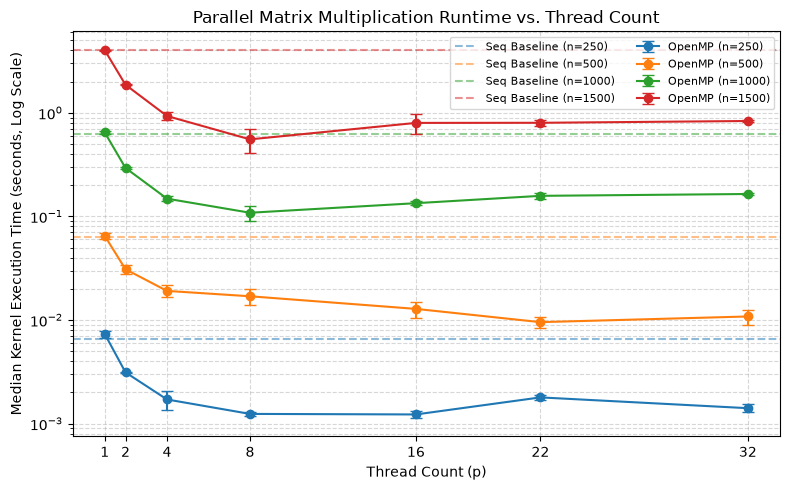

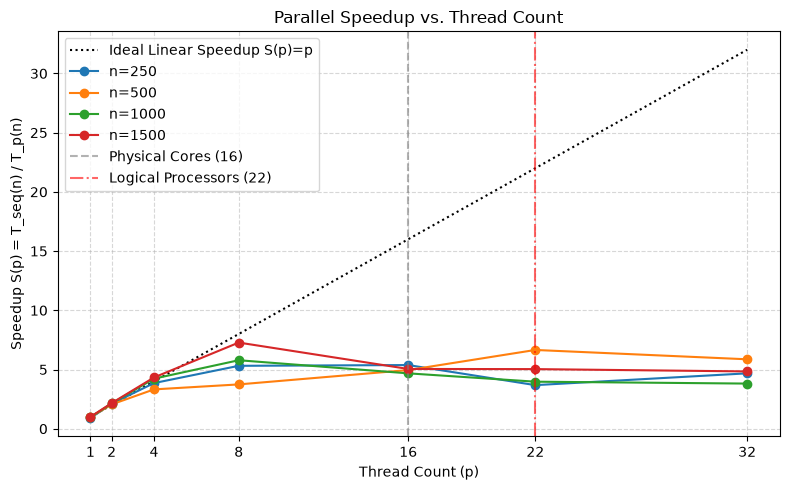

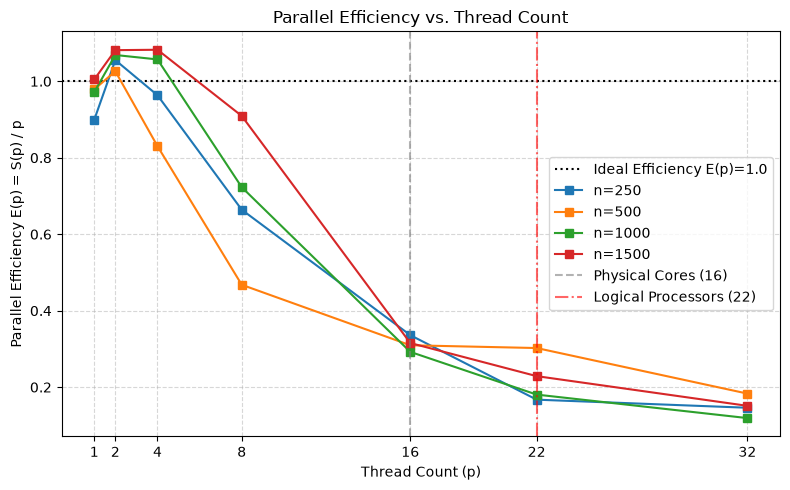

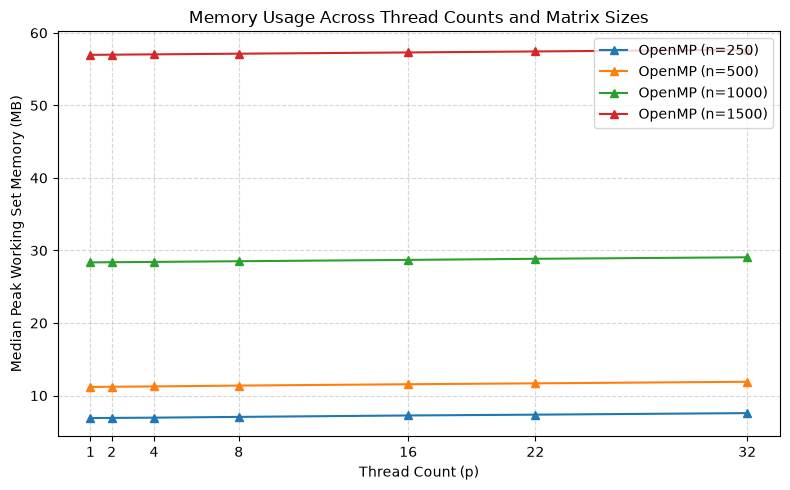

In [8]:
omp_df = summary_df[summary_df["method"] == "OpenMP_Parallel"]
seq_df = summary_df[summary_df["method"] == "Sequential_Baseline"]

plt.figure(figsize=(8, 5))
for n in matrix_sizes:
    sub = omp_df[omp_df["n"] == n].sort_values("threads")
    t_seq_val = seq_df[seq_df["n"] == n]["median_time_s"].values[0]
    line = plt.errorbar(sub["threads"], sub["median_time_s"], yerr=sub["iqr_time_s"], marker="o", capsize=4, label=f"OpenMP (n={n})")
    plt.axhline(t_seq_val, linestyle="--", alpha=0.5, color=line[0].get_color(), label=f"Seq Baseline (n={n})")
plt.yscale("log")
plt.xticks(thread_counts)
plt.xlabel("Thread Count (p)")
plt.ylabel("Median Kernel Execution Time (seconds, Log Scale)")
plt.title("Parallel Matrix Multiplication Runtime vs. Thread Count")
plt.legend(ncol=2, fontsize=8)
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("figures/runtime_vs_threads.png", dpi=300)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(thread_counts, thread_counts, linestyle=":", color="black", label="Ideal Linear Speedup S(p)=p")
for n in matrix_sizes:
    sub = omp_df[omp_df["n"] == n].sort_values("threads")
    plt.plot(sub["threads"], sub["speedup"], marker="o", label=f"n={n}")
plt.axvline(16, linestyle="--", color="gray", alpha=0.6, label="Physical Cores (16)")
plt.axvline(22, linestyle="-.", color="red", alpha=0.6, label="Logical Processors (22)")
plt.xticks(thread_counts)
plt.xlabel("Thread Count (p)")
plt.ylabel("Speedup S(p) = T_seq(n) / T_p(n)")
plt.title("Parallel Speedup vs. Thread Count")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("figures/speedup_vs_threads.png", dpi=300)
plt.show()

plt.figure(figsize=(8, 5))
plt.axhline(1.0, linestyle=":", color="black", label="Ideal Efficiency E(p)=1.0")
for n in matrix_sizes:
    sub = omp_df[omp_df["n"] == n].sort_values("threads")
    plt.plot(sub["threads"], sub["efficiency"], marker="s", label=f"n={n}")
plt.axvline(16, linestyle="--", color="gray", alpha=0.6, label="Physical Cores (16)")
plt.axvline(22, linestyle="-.", color="red", alpha=0.6, label="Logical Processors (22)")
plt.xticks(thread_counts)
plt.xlabel("Thread Count (p)")
plt.ylabel("Parallel Efficiency E(p) = S(p) / p")
plt.title("Parallel Efficiency vs. Thread Count")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("figures/efficiency_vs_threads.png", dpi=300)
plt.show()

plt.figure(figsize=(8, 5))
for n in matrix_sizes:
    sub = omp_df[omp_df["n"] == n].sort_values("threads")
    plt.plot(sub["threads"], sub["median_memory_mb"], marker="^", label=f"OpenMP (n={n})")
plt.xticks(thread_counts)
plt.xlabel("Thread Count (p)")
plt.ylabel("Median Peak Working Set Memory (MB)")
plt.title("Memory Usage Across Thread Counts and Matrix Sizes")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("figures/memory_vs_threads.png", dpi=300)
plt.show()